# Optimization programming Assignment

In [98]:
import numpy as np

from algorithms import (
    simplex, two_phase, dual, bisection, newton, iterative, steepest_descent,
    steepest_descent_fixed, newton_multivariable, conjugate_gradient, quasi_newton,
    rank_one, dfp, bfgs,
)

from common import (
    show_result, plot_lp, plot_phases, plot_scalar, quadratic, plot_quadratic,
)

# 1. Simplex Method

$$\min z=-2x_1-5x_2$$
$$x_1\leq4,\quad x_2\leq6,\quad x_1+x_2\leq8,\quad x_1,x_2\geq0.$$

Introduce slack variables $x_3,x_4,x_5$ and start with basis $(x_3,x_4,x_5)$.
Use the most negative reduced cost and the minimum ratio test.

In [99]:
A = np.array([[1, 0, 1, 0, 0],
              [0, 1, 0, 1, 0],
              [1, 1, 0, 0, 1]], dtype=float)
b = np.array([4, 6, 8], dtype=float)
c = np.array([-2, -5, 0, 0, 0], dtype=float)
basis = [2, 3, 4]

In [100]:
result = simplex(A, b, c, basis)
show_result(result)

Status: optimal
Solution: [2. 6. 2. 0. 0.]
Objective: -34.0
Basis (zero-based): [2 1 0]


# 2. Two-Phase Method

$$\min z=3x_1+x_2,\qquad 2x_1+x_2=2,\qquad x_1,x_2\geq0.$$

After row normalization, Phase I minimizes $w=a_1$ subject to
$x_1+\tfrac12x_2+a_1=1$, $x_1,x_2,a_1\geq0$.
After reaching $w=0$, remove artificial variables and minimize the original $z$ in Phase II.

In [101]:
A = np.array([[2, 1]], dtype=float)
b = np.array([2], dtype=float)
c = np.array([3, 1], dtype=float)

In [102]:
result = two_phase(A, b, c)
show_result(result)

Status: optimal
Solution: [0. 2.]
Objective: 2.0
Basis (zero-based): [1]


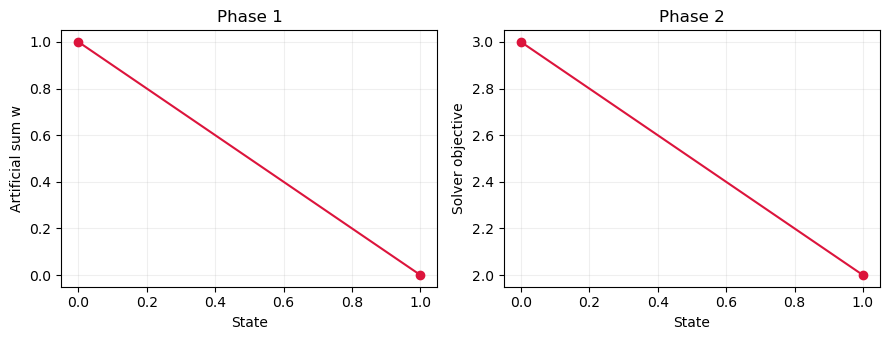

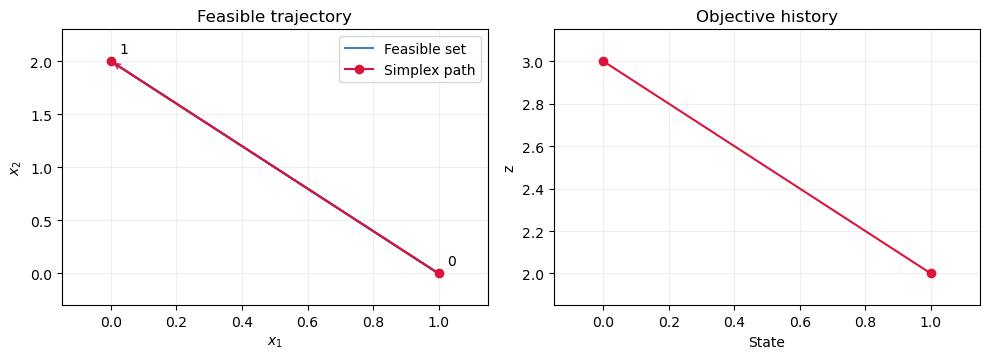

In [103]:
plot_phases(result[3])
history = [h for h in result[3] if h["phase"] == 2]
plot_lp(np.vstack((A, -A)), np.r_[b, -b], history)

# 3. Dual Method

$$\max 4y_1+6y_2+8y_3$$
$$y_1+y_3\leq-2,\quad y_2+y_3\leq-5,\quad y_1,y_2,y_3\leq0.$$

This is the dual of problem 1 in equality standard form:
$\max b^Ty$ subject to $A^Ty\leq c$, with unrestricted dual variables before these constraints.
Form and solve the dual using two-phase; this is not dual simplex.
Internal Phase II minimizes $-b^Ty$.

In [104]:
A = np.array([[1, 0, 1, 0, 0],
              [0, 1, 0, 1, 0],
              [1, 1, 0, 0, 1]], dtype=float)
b = np.array([4, 6, 8], dtype=float)
c = np.array([-2, -5, 0, 0, 0], dtype=float)

In [105]:
result = dual(A, b, c)
show_result(result)
print("Dual slack:", c - A.T @ result[0])

Status: optimal
Solution: [ 0. -3. -2.]
Objective: -34.0
Basis (zero-based): [ 5  4  0  9 10]
Dual slack: [0. 0. 0. 3. 2.]


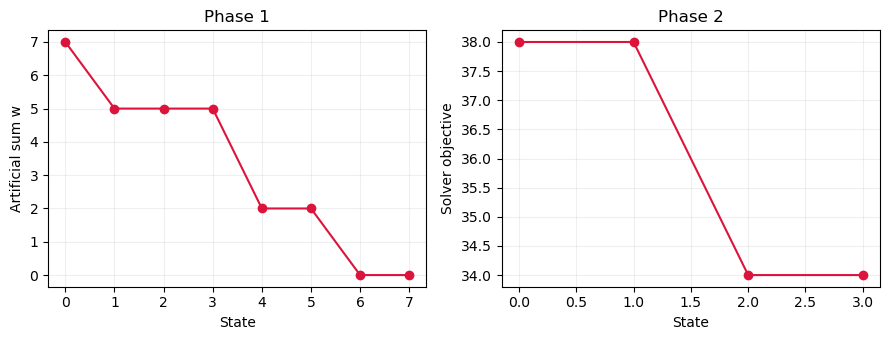

In [106]:
plot_phases(result[3])

# 4. Bisection Method

$$\min_{x\in\mathbb{R}} f(x)=x^4+2x^2-8x+3.$$

Bisect $f'(x)=0$ on $[0,3]$, where $f'(0)<0<f'(3)$.

In [107]:
def f(x):
    return x**4 + 2*x**2 - 8*x + 3


def df(x):
    return 4*x**3 + 4*x - 8

a = 0
b = 3

In [108]:
result = bisection(f, df, a, b)
show_result(result)

Status: bracket_converged
Solution: 1.0000000018626451
Objective: -2.0
Updates: 28
Derivative / gradient norm: 2.9802322387695312e-08


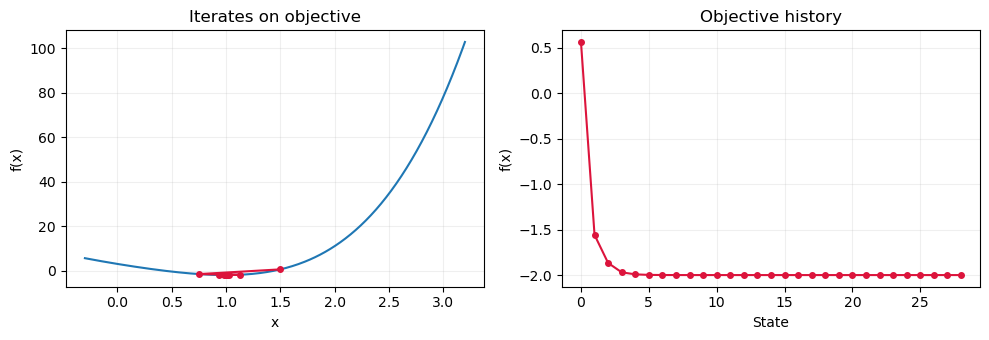

In [109]:
plot_scalar(f, result[2], -0.3, 3.2)

# 5. Newton's Method

$$\min_{x\in\mathbb{R}} f(x)=x^4+2x^2-8x+3.$$

$$x_{k+1}=x_k-\frac{f'(x_k)}{f''(x_k)},\qquad x_0=3.$$
Use full scalar Newton steps.

In [110]:
def f(x):
    return x**4 + 2*x**2 - 8*x + 3


def df(x):
    return 4*x**3 + 4*x - 8


def ddf(x):
    return 12*x**2 + 4

x0 = 3

In [111]:
result = newton(f, df, ddf, x0)
show_result(result)

Status: stationary
Solution: 1.0000000002185543
Objective: -2.0
Updates: 6
Derivative / gradient norm: 3.496868572483436e-09


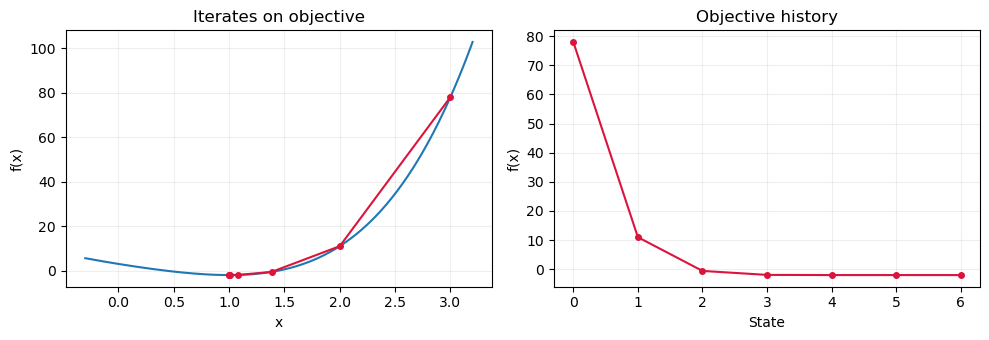

In [112]:
plot_scalar(f, result[2], -0.3, 3.2)

# 6. Iterative Method

$$\min_{x\in\mathbb{R}} f(x)=x^4+2x^2-8x+3.$$

$$x_{k+1}=h(x_k)=\sqrt[3]{2-x_k},\qquad x_0=0.$$
This rearranges $f'(x)=0$; $|h'(1)|=1/3<1$.

In [113]:
def f(x):
    return x**4 + 2*x**2 - 8*x + 3


def df(x):
    return 4*x**3 + 4*x - 8


def h(x):
    return np.cbrt(2 - x)

x0 = 0

In [114]:
result = iterative(f, df, h, x0)
show_result(result)

Status: stationary
Solution: 0.9999999997591641
Objective: -2.0
Updates: 20
Derivative / gradient norm: 3.853374508366869e-09


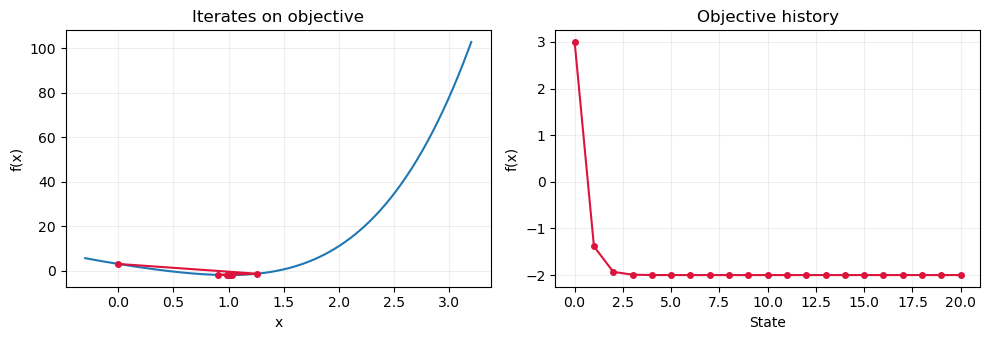

In [115]:
plot_scalar(f, result[2], -0.3, 3.2)

# 7. Steepest Descent Method

$$\min_{(x,y,z)\in\mathbb{R}^3} f(x,y,z)=(x-1)^2+(y+7)^4+(z-3)^2,$$
$$X_0=(2,-5,4),\qquad \nabla f=(2(x-1),\;4(y+7)^3,\;2(z-3)).$$

Use the negative gradient direction and strong Wolfe line search. The objective is not quadratic, so omit `Q`.


In [116]:
def f(X):
    x, y, z = X
    return (x - 1)**2 + (y + 7)**4 + (z - 3)**2


def grad(X):
    x, y, z = X
    return np.array([2*(x - 1), 4*(y + 7)**3, 2*(z - 3)])


x0 = np.array([2, -5, 4], dtype=float)


In [117]:
result = steepest_descent(f, grad, x0)
show_result(result)


Status: stationary
Solution: [ 1. -7.  3.]
Objective: 0.0
Updates: 2
Derivative / gradient norm: 0.0


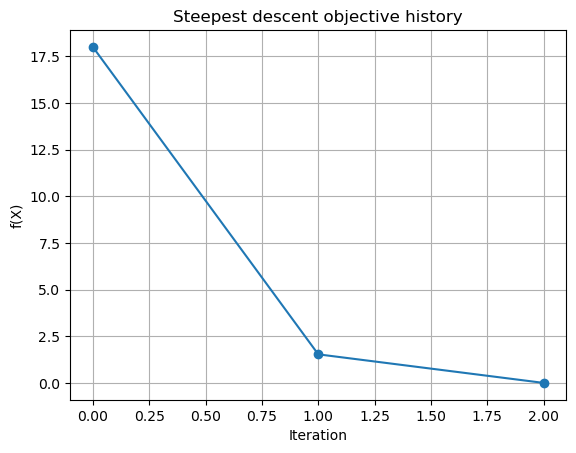

In [118]:
import matplotlib.pyplot as plt

plt.plot([s["fx"] for s in result[2]], marker="o")
plt.xlabel("Iteration")
plt.ylabel("f(X)")
plt.title("Steepest descent objective history")
plt.grid(True)
plt.show()


import matplotlib.pyplot as plt

history = result[2]
iterations = np.arange(len(history))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(iterations, [s["fx"] for s in history], "o-")
axes[0].set(xlabel="Iteration", ylabel="f(X)", title="Objective convergence")
trajectory = np.array([s["x"] for s in history])
for j, name in enumerate(("x", "y", "z")):
    axes[1].plot(iterations, trajectory[:, j], "o-", label=name)
axes[1].set(xlabel="Iteration", ylabel="Coordinate", title="Steepest descent iterates")
axes[1].legend()
for ax in axes:
    ax.set_xticks(iterations)
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


In [119]:
Q = np.array([[4, 1], [1, 3]], dtype=float)
b = np.array([1, 2], dtype=float)
x0 = np.array([3, -2], dtype=float)
f, grad, hess = quadratic(Q, b)

alpha = 0.1

In [120]:
result = steepest_descent_fixed(f, grad, x0, alpha=alpha)
show_result(result)

Status: stationary
Solution: [0.09090909 0.63636363]
Objective: -0.6818181818181819
Updates: 76
Derivative / gradient norm: 9.40959459940031e-09


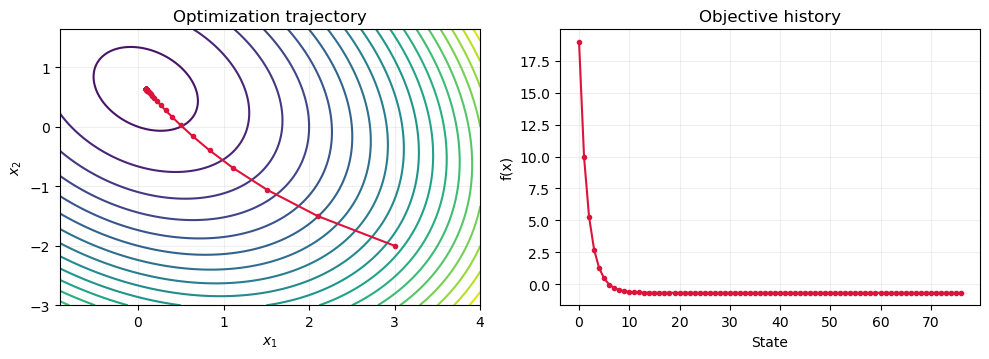

In [121]:
plot_quadratic(Q, b, result[2])

# 9. Newton's Algorithm for Multivariable Minimization

$$\min_{(x,y,z)\in\mathbb{R}^3} f(x,y,z)=(x-1)^2+(y+7)^4+(z-3)^2,$$
$$X_0=(2,-5,4),\qquad \nabla f=(2(x-1),\;4(y+7)^3,\;2(z-3)).$$
$$\nabla^2 f(X)=\operatorname{diag}(2,\;12(y+7)^2,\;2).$$

Use the same objective and starting point as steepest descent in Section 7.
Solve $\nabla^2 f(X_k)d_k=-\nabla f(X_k)$, then take the full step $X_{k+1}=X_k+d_k$.
The unique minimum is $X^*=(1,-7,3)$ with $f(X^*)=0$. The Hessian is singular at the minimum, so convergence is checked using the gradient tolerance.


In [140]:
def f(X):
    x, y, z = X
    return (x - 1)**2 + (y + 7)**4 + (z - 3)**2


def grad(X):
    x, y, z = X
    return np.array([2*(x - 1), 4*(y + 7)**3, 2*(z - 3)])


x0 = np.array([2, -5, 4], dtype=float)


def hess(X):
    x, y, z = X
    return np.diag([2.0, 12*(y + 7)**2, 2.0])


In [141]:
result = newton_multivariable(f, grad, hess, x0)
show_result(result)

Status: stationary
Solution: [ 1.         -6.99864672  3.        ]
Objective: 3.353893985013601e-12
Updates: 18
Derivative / gradient norm: 9.913385373907581e-09


In [ ]:
import matplotlib.pyplot as plt

history = result[2]
iterations = np.arange(len(history))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(iterations, [s["fx"] for s in history], "o-")
axes[0].set(xlabel="Iteration", ylabel="f(X)", title="Newton objective convergence")
trajectory = np.array([s["x"] for s in history])
for j, name in enumerate(("x", "y", "z")):
    axes[1].plot(iterations, trajectory[:, j], "o-", label=name)
axes[1].set(xlabel="Iteration", ylabel="Coordinate", title="Newton iterates")
axes[1].legend()
for ax in axes:
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


# 10. Conjugate Gradient Algorithm

$$\min_{x\in\mathbb{R}^2} f(x)=\tfrac12x^TQx-b^Tx,$$
$$Q=\begin{bmatrix}4&1\\1&3\end{bmatrix},\quad
b=\begin{bmatrix}1\\2\end{bmatrix},\quad x_0=\begin{bmatrix}3\\-2\end{bmatrix}.$$

Use $Q$-conjugate directions to solve $Qx=b$. Here $Q$ is symmetric positive definite.

In [125]:
Q = np.array([[4, 1], [1, 3]], dtype=float)
b = np.array([1, 2], dtype=float)
x0 = np.array([3, -2], dtype=float)
f, grad, hess = quadratic(Q, b)

In [126]:
result = conjugate_gradient(Q, b, x0)
show_result(result)

Status: stationary
Solution: [0.09090909 0.63636364]
Objective: -0.6818181818181818
Updates: 2
Derivative / gradient norm: 5.551115123125783e-16


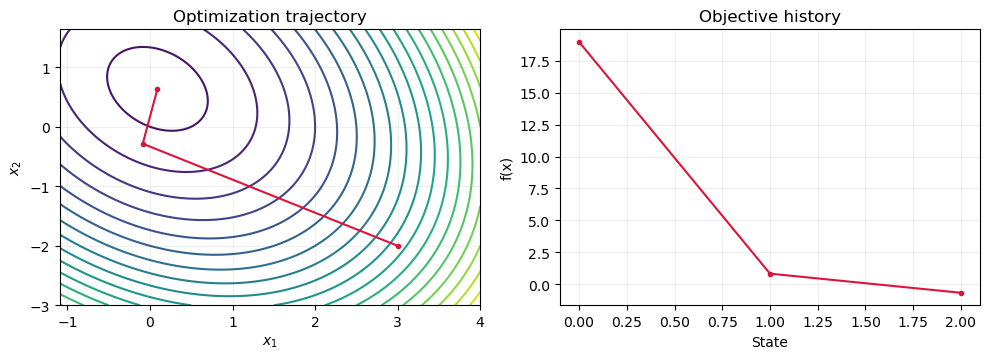

In [127]:
plot_quadratic(Q, b, result[2])

# 11. Quasi-Newton Method

$$\min_{x\in\mathbb{R}^2} f(x)=\tfrac12x^TQx-b^Tx,$$
$$Q=\begin{bmatrix}4&1\\1&3\end{bmatrix},\quad
b=\begin{bmatrix}1\\2\end{bmatrix},\quad x_0=\begin{bmatrix}3\\-2\end{bmatrix}.$$

$d_k=-H_kg_k$, with $H_{k+1}y_k=s_k$, $H_0=I$. The shared iteration defaults to BFGS; it is not a separate update. Here $s=x_{k+1}-x_k$, $y=g_{k+1}-g_k$; line steps are exact for this quadratic.

In [128]:
Q = np.array([[4, 1], [1, 3]], dtype=float)
b = np.array([1, 2], dtype=float)
x0 = np.array([3, -2], dtype=float)
f, grad, hess = quadratic(Q, b)

In [129]:
result = quasi_newton(f, grad, x0, Q=Q)
show_result(result)

Status: stationary
Solution: [0.09090909 0.63636364]
Objective: -0.6818181818181818
Updates: 2
Derivative / gradient norm: 4.577566798522237e-16


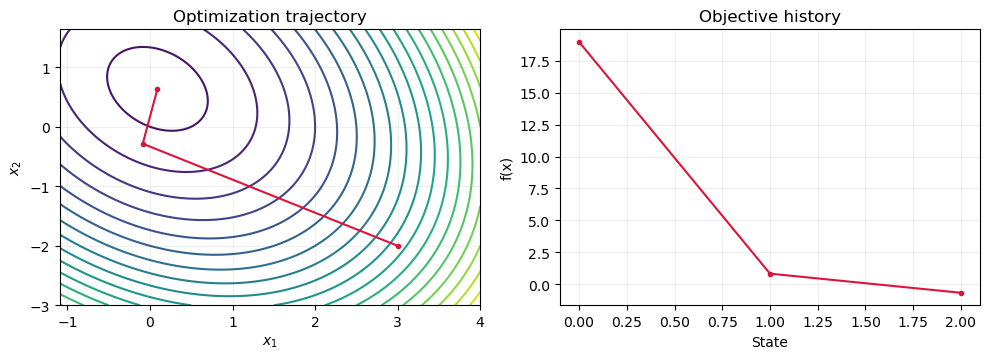

In [130]:
plot_quadratic(Q, b, result[2])

# 12. Rank-One Correction Algorithm (SR1)

$$\min_{x\in\mathbb{R}^2} f(x)=\tfrac12x^TQx-b^Tx,$$
$$Q=\begin{bmatrix}4&1\\1&3\end{bmatrix},\quad
b=\begin{bmatrix}1\\2\end{bmatrix},\quad x_0=\begin{bmatrix}3\\-2\end{bmatrix}.$$

$H_{k+1}=H_k+vv^T/(v^Ty)$, where $v=s-H_ky$ and $H_0=I$. Unsafe updates are skipped. Here $s=x_{k+1}-x_k$, $y=g_{k+1}-g_k$; line steps are exact for this quadratic.

In [131]:
Q = np.array([[4, 1], [1, 3]], dtype=float)
b = np.array([1, 2], dtype=float)
x0 = np.array([3, -2], dtype=float)
f, grad, hess = quadratic(Q, b)

In [132]:
result = rank_one(f, grad, x0, Q=Q)
show_result(result)

Status: stationary
Solution: [0.09090909 0.63636364]
Objective: -0.6818181818181818
Updates: 2
Derivative / gradient norm: 2.220446049250313e-16


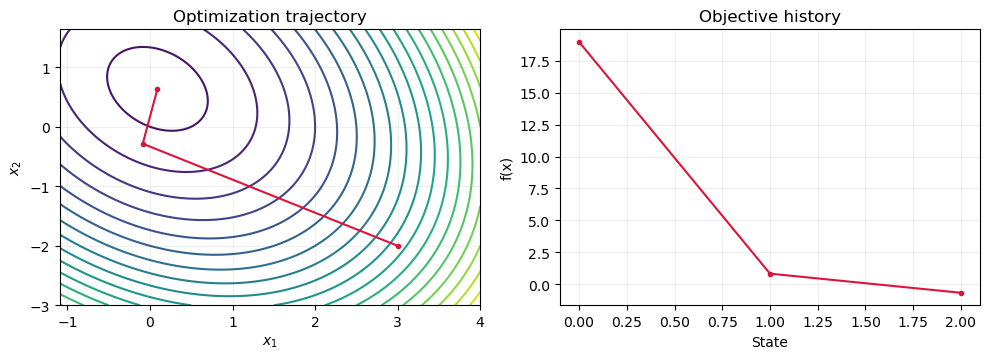

In [133]:
plot_quadratic(Q, b, result[2])

# 13. DFP Algorithm

$$\min_{x\in\mathbb{R}^2} f(x)=\tfrac12x^TQx-b^Tx,$$
$$Q=\begin{bmatrix}4&1\\1&3\end{bmatrix},\quad
b=\begin{bmatrix}1\\2\end{bmatrix},\quad x_0=\begin{bmatrix}3\\-2\end{bmatrix}.$$

$H_{k+1}=H_k+ss^T/(s^Ty)-H_kyy^TH_k/(y^TH_ky)$, with $H_0=I$. Here $s=x_{k+1}-x_k$, $y=g_{k+1}-g_k$; line steps are exact for this quadratic.

In [134]:
Q = np.array([[4, 1], [1, 3]], dtype=float)
b = np.array([1, 2], dtype=float)
x0 = np.array([3, -2], dtype=float)
f, grad, hess = quadratic(Q, b)

In [135]:
result = dfp(f, grad, x0, Q=Q)
show_result(result)

Status: stationary
Solution: [0.09090909 0.63636364]
Objective: -0.6818181818181818
Updates: 2
Derivative / gradient norm: 6.280369834735101e-16


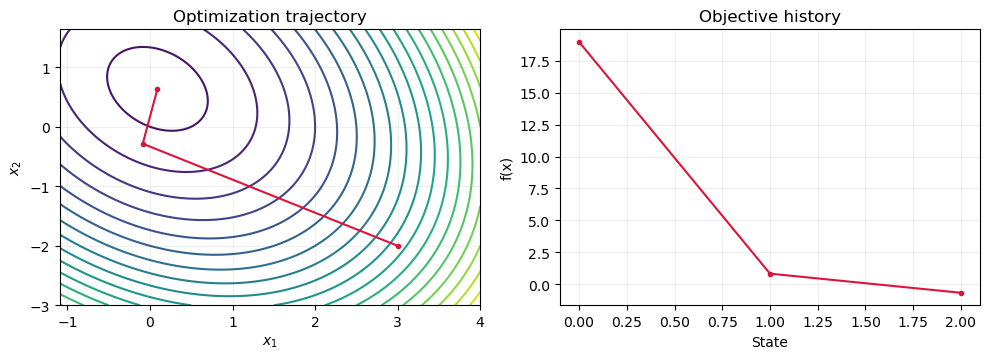

In [136]:
plot_quadratic(Q, b, result[2])

# 14. BFGS Algorithm

$$\min_{x\in\mathbb{R}^2} f(x)=\tfrac12x^TQx-b^Tx,$$
$$Q=\begin{bmatrix}4&1\\1&3\end{bmatrix},\quad
b=\begin{bmatrix}1\\2\end{bmatrix},\quad x_0=\begin{bmatrix}3\\-2\end{bmatrix}.$$

$H_{k+1}=(I-\rho sy^T)H_k(I-\rho ys^T)+\rho ss^T$, with $\rho=1/(s^Ty)$ and $H_0=I$. Here $s=x_{k+1}-x_k$, $y=g_{k+1}-g_k$; line steps are exact for this quadratic.

In [ ]:
Q = np.array([[4, 1], [1, 3]], dtype=float)
b = np.array([1, 2], dtype=float)
x0 = np.array([3, -2], dtype=float)
f, grad, hess = quadratic(Q, b)

In [138]:
result = bfgs(f, grad, x0, Q=Q)
show_result(result)

Status: stationary
Solution: [0.09090909 0.63636364]
Objective: -0.6818181818181818
Updates: 2
Derivative / gradient norm: 4.577566798522237e-16


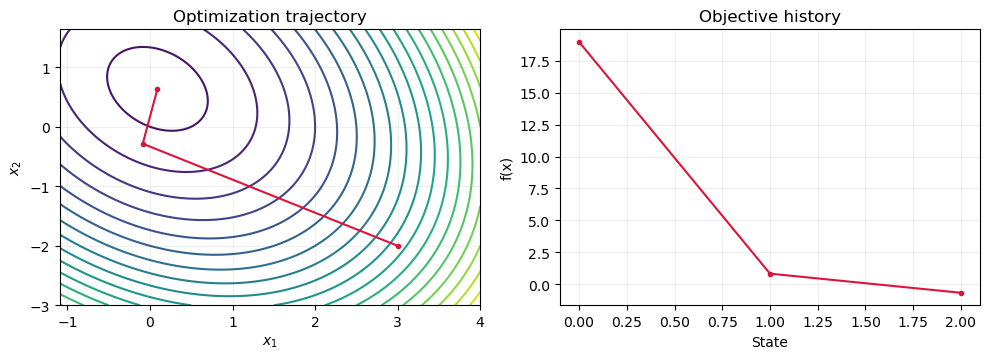

In [139]:
plot_quadratic(Q, b, result[2])